Net1(
  (net): Sequential(
    (0): Linear(in_features=1, out_features=256, bias=True)
    (1): Tanh()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): Tanh()
    (4): Linear(in_features=256, out_features=1, bias=True)
  )
)


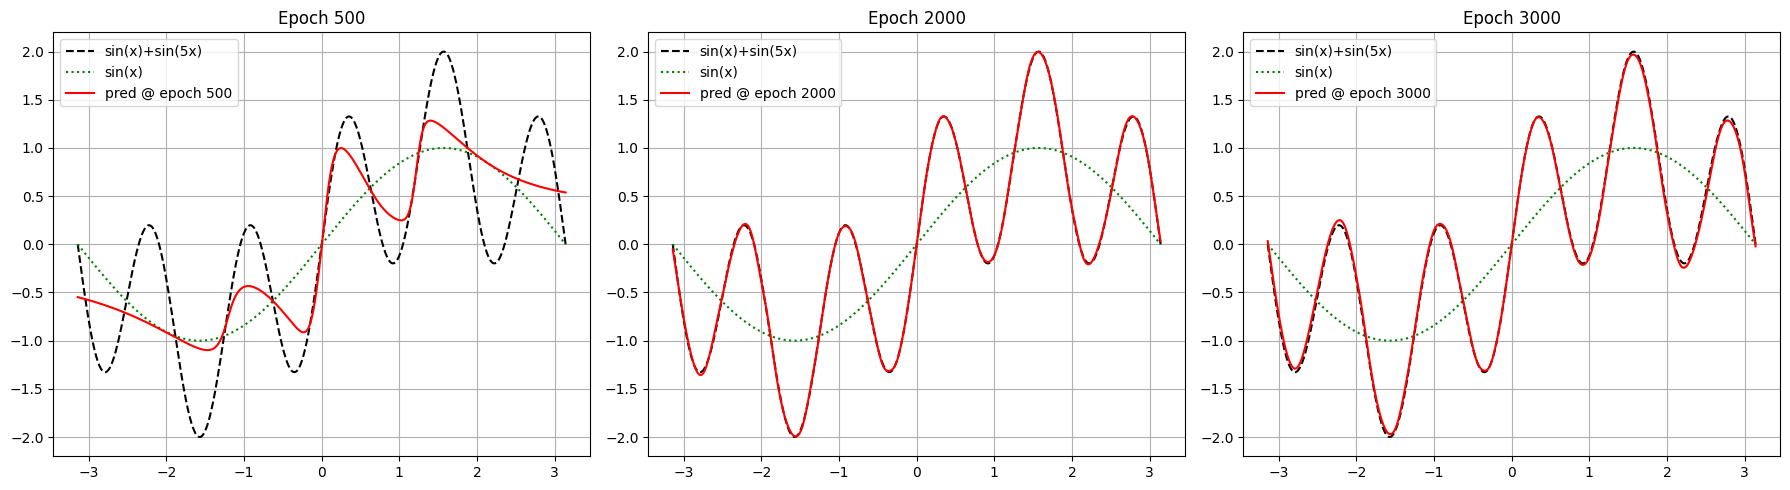

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)

def f(x):
    return torch.sin(x) + torch.sin(5 * x)

x_min, x_max = -3.14159, 3.14159
x_train = torch.linspace(x_min, x_max, 500).unsqueeze(1)
y_train = f(x_train)

x_test = torch.linspace(x_min, x_max, 1000).unsqueeze(1)
y_test = f(x_test)

class Net1(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 256),
            nn.Tanh(),
            nn.Linear(256, 256),
            nn.Tanh(),
            nn.Linear(256, 1)
        )
    def forward(self, x):
        return self.net(x)

model1 = Net1()
print(model1)

optimizer = torch.optim.Adam(model1.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

epochs_to_show = [500, 2000, 3000]
snapshots = {}

for epoch in range(1, 3001):
    model1.train()
    optimizer.zero_grad()
    pred = model1(x_train)
    loss = loss_fn(pred, y_train)
    loss.backward()
    optimizer.step()

    if epoch in epochs_to_show:
        model1.eval()
        with torch.no_grad():
            snapshots[epoch] = model1(x_test).clone()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, ep in zip(axes, epochs_to_show):
    ax.plot(x_test.numpy(), y_test.numpy(), 'k--', label='sin(x)+sin(5x)')
    ax.plot(x_test.numpy(), torch.sin(x_test).numpy(), 'g:', label='sin(x)')
    ax.plot(x_test.numpy(), snapshots[ep].numpy(), 'r-', label=f'pred @ epoch {ep}')
    ax.set_title(f'Epoch {ep}')
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

Net2(
  (ff): FourierFeatures()
  (net): Sequential(
    (0): Linear(in_features=128, out_features=256, bias=True)
    (1): Tanh()
    (2): Linear(in_features=256, out_features=1, bias=True)
  )
)


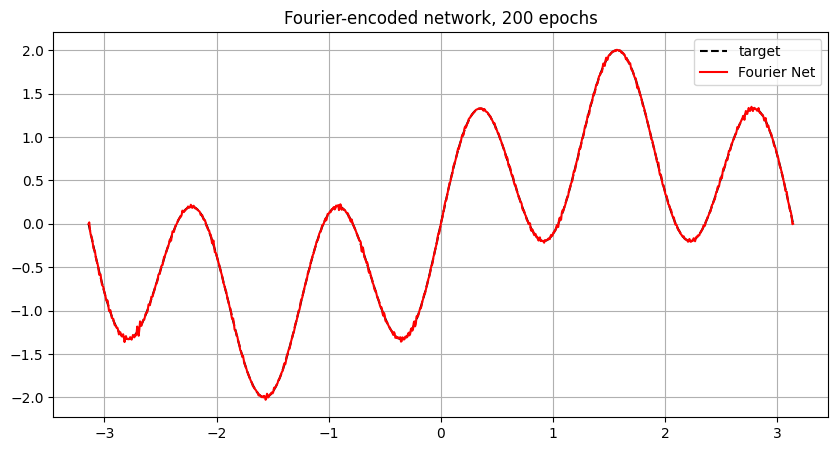

In [2]:
class FourierFeatures(nn.Module):
    def __init__(self, n_features=128, sigma=10):
        super().__init__()
        assert n_features % 2 == 0
        self.n_freqs = n_features // 2
        # B: (1, n_freqs)
        self.register_buffer('B', torch.randn(1, self.n_freqs) * sigma)

    def forward(self, x):
        proj = 2 * torch.pi * x @ self.B
        return torch.cat([torch.sin(proj), torch.cos(proj)], dim=-1)  # (B, 128)

class Net2(nn.Module):
    def __init__(self):
        super().__init__()
        self.ff = FourierFeatures(128, 10)
        self.net = nn.Sequential(
            nn.Linear(128, 256),
            nn.Tanh(),
            nn.Linear(256, 1)
        )
    def forward(self, x):
        return self.net(self.ff(x))

model2 = Net2()
print(model2)

optimizer = torch.optim.Adam(model2.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

for epoch in range(200):
    model2.train()
    optimizer.zero_grad()
    loss = loss_fn(model2(x_train), y_train)
    loss.backward()
    optimizer.step()

model2.eval()
with torch.no_grad():
    y_pred2 = model2(x_test)

plt.figure(figsize=(10, 5))
plt.plot(x_test.numpy(), y_test.numpy(), 'k--', label='target')
plt.plot(x_test.numpy(), y_pred2.numpy(), 'r-', label='Fourier Net')
plt.title('Fourier-encoded network, 200 epochs')
plt.legend(); plt.grid(True)
plt.show()

Net3(
  (ff): FourierFeatures()
  (net): Sequential(
    (0): Linear(in_features=128, out_features=256, bias=True)
    (1): Linear(in_features=256, out_features=1, bias=True)
  )
)


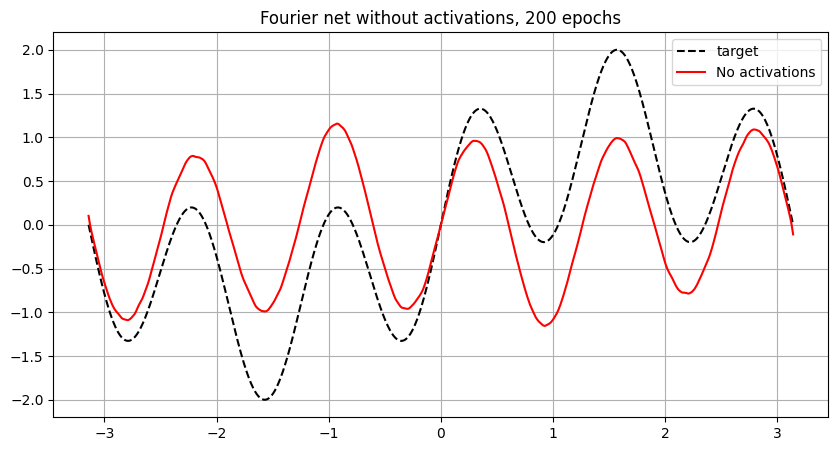

In [3]:
class Net3(nn.Module):
    def __init__(self):
        super().__init__()
        self.ff = FourierFeatures(128, 10)
        self.net = nn.Sequential(
            nn.Linear(128, 256),
            nn.Linear(256, 1)
        )
    def forward(self, x):
        return self.net(self.ff(x))

model3 = Net3()
print(model3)

optimizer = torch.optim.Adam(model3.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

for epoch in range(200):
    model3.train()
    optimizer.zero_grad()
    loss = loss_fn(model3(x_train), y_train)
    loss.backward()
    optimizer.step()

model3.eval()
with torch.no_grad():
    y_pred3 = model3(x_test)

plt.figure(figsize=(10, 5))
plt.plot(x_test.numpy(), y_test.numpy(), 'k--', label='target')
plt.plot(x_test.numpy(), y_pred3.numpy(), 'r-', label='No activations')
plt.title('Fourier net without activations, 200 epochs')
plt.legend(); plt.grid(True)
plt.show()